# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn (including DecisionTreeClassifier, RandomForestClassifier and GradingBoostingClassifier)
- Matplotlib


In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Model training and evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Display settings
pd.set_option('display.max_columns', None)


## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


Dataset shape: (29504, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
unique,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,27903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,14850.475563,0.546638,33766.893303,NaN,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,NaN,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,NaN,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,NaN,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,NaN,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,NaN,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000


Missing values:
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64
Duplicate rows: 3
Duplicate customer IDs: 3


,income,age,num_dependents,num_accts
count,29504.000000,29504.000000,29504.000000,29504.000000
mean,33766.893303,34.773454,1.140998,2.458345
std,29379.202710,11.369865,0.348025,19.497380
min,-65600.000000,19.000000,1.000000,0.000000
25%,13550.000000,26.000000,1.000000,2.000000
50%,23310.000000,32.000000,1.000000,2.000000
75%,41690.000000,40.000000,1.000000,3.000000
max,159450.000000,132.000000,2.000000,3345.000000


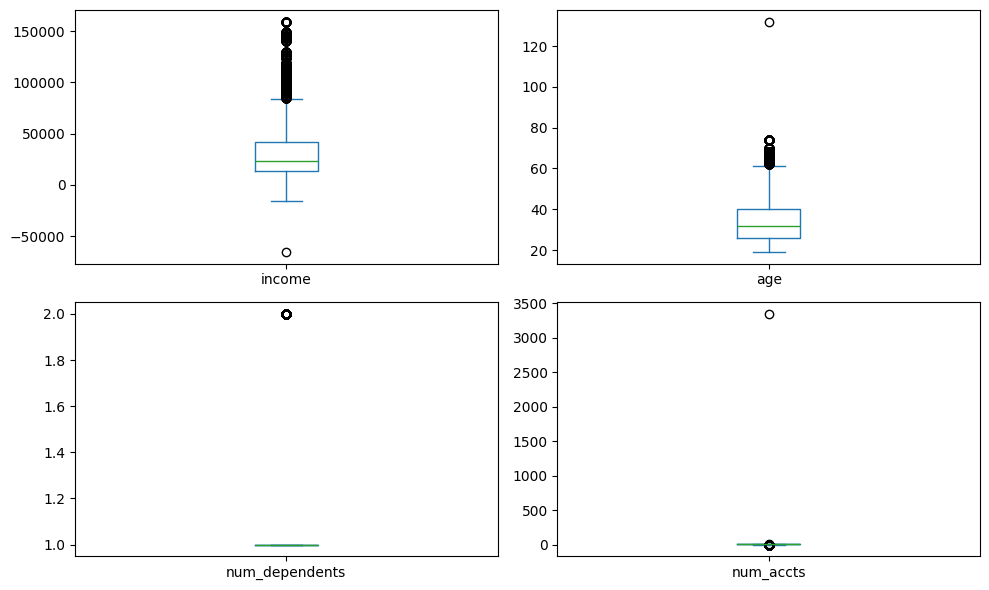

In [ ]:
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv"

df = pd.read_csv(url)

display(df.head())

print("Dataset shape:", df.shape)
df.info()

display(df.describe(include='all'))

print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df['customer_id'].duplicated().sum())


display(df[['income', 'age', 'num_dependents', 'num_accts']].describe())

df[['income', 'age', 'num_dependents', 'num_accts']].plot(
    kind='box',
    subplots=True,
    layout=(2, 2),
    figsize=(10, 6),
    sharey=False
)

plt.tight_layout()
plt.show()


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1.  One thing that stood out was that the dataset has over 29,000 customer records, but there are some unusual values. For example, one customer has a negative income of $65,600, another has an age of 132, and someone has 3,345 accounts, which seems unrealistic. I also noticed 2 missing values in the new_car column and 3 duplicate rows. These are things we should clean before building our model.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [ ]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

df_clean = df_clean[df_clean['income'] >= 0]
df_clean = df_clean[df_clean['age'].between(18, 100)]
df_clean = df_clean[df_clean['num_accts'] <= 20]
df_clean['new_car'] = df_clean['new_car'].fillna(
    df_clean['new_car'].mode()[0]
)

print("Female values before cleaning:")
print(df_clean['female'].value_counts(dropna=False))

df_clean['female'] = pd.to_numeric(
    df_clean['female'], errors='coerce'
)

df_clean.loc[
    ~df_clean['female'].isin([0, 1]), 'female'
] = np.nan

df_clean['female'] = df_clean['female'].fillna(
    df_clean['female'].mode()[0]
).astype(int)

df_clean = df_clean.drop(
    columns=['customer_id', 'product']
)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

display(df_clean.head())


Female values before cleaning:
female
0    27898
1     1598
M        1
Name: count, dtype: int64
Original dataset shape: (29504, 15)
Cleaned dataset shape: (29497, 13)

Missing values:
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
dtype: int64

Duplicate rows:
29035


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
2,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
3,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
4,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
6,0,4330,0,22,2,1,1,0,0.0,3,0,0,0


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed duplicate rows and unrealistic outliers, such as negative income, ages over 100, and customers with more than 20 accounts. For the missing values in the new car column, I filled them using the most common value instead of deleting the rows. I chose this approach because it allowed me to keep more data while removing values that could negatively affect the model.

2.6  I removed customer id and product because they wouldn't be useful for predicting whether a customer answers their phone call. The customer id is just a unique identifier, while product contains information that is only available after the customer answers. Keeping product could cause data leakage and make the model seem more accurate than it actually is.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [ ]:
df_clean['answered'] = df_clean['answered'].astype(bool)

for col in df_clean.columns:
    if col != 'answered':
        df_clean[col] = df_clean[col].astype(int)

print(df_clean.dtypes)

display(df_clean.head())


answered           bool
income            int64
female            int64
age               int64
job               int64
num_dependents    int64
rent              int64
own_res           int64
new_car           int64
chk_acct          int64
sav_acct          int64
num_accts         int64
mobile            int64
dtype: object


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
3,False,4330,0,24,2,2,1,0,0,1,3,1,0
4,False,4330,0,22,2,1,1,0,0,3,0,0,0
6,False,4330,0,22,2,1,1,0,0,3,0,0,0


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [ ]:
df_clean['job'] = df_clean['job'].astype('category')
df_clean['chk_acct'] = df_clean['chk_acct'].astype('category')
df_clean['sav_acct'] = df_clean['sav_acct'].astype('category')

print(df_clean.dtypes)

display(df_clean.head())


answered              bool
income               int64
female               int64
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
3,False,4330,0,24,2,2,1,0,0,1,3,1,0
4,False,4330,0,22,2,1,1,0,0,3,0,0,0
6,False,4330,0,22,2,1,1,0,0,3,0,0,0


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



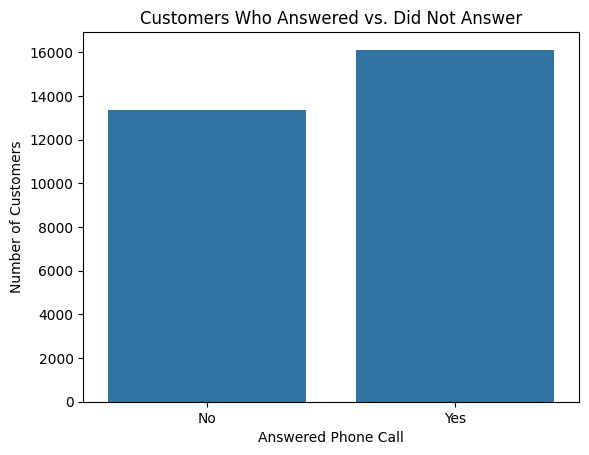

In [ ]:
sns.countplot(data=df_clean, x='answered')
plt.title('Customers Who Answered vs. Did Not Answer')
plt.xlabel('Answered Phone Call')
plt.ylabel('Number of Customers')
plt.xticks([0, 1], ['No', 'Yes'])
plt.show()


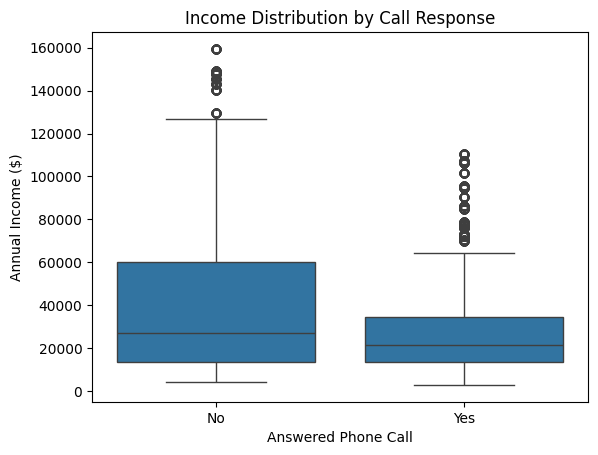

In [ ]:
sns.boxplot(data=df_clean, x='answered', y='income')
plt.title('Income Distribution by Call Response')
plt.xlabel('Answered Phone Call')
plt.ylabel('Annual Income ($)')
plt.xticks([0, 1], ['No', 'Yes'])
plt.show()


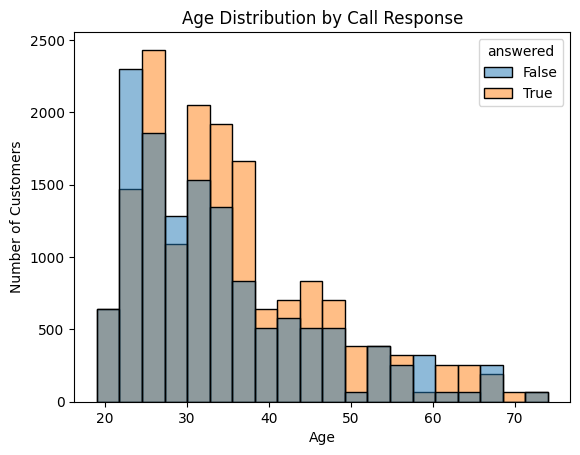

In [ ]:
sns.histplot(
    data=df_clean,
    x='age',
    hue='answered',
    bins=20,
    multiple='layer',
    alpha=0.5
)
plt.title('Age Distribution by Call Response')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()


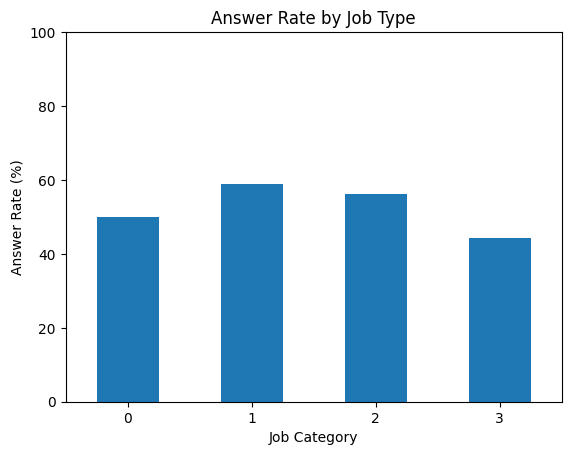

In [ ]:
job_answer = df_clean.groupby(
    'job', observed=True
)['answered'].mean() * 100

job_answer.plot(kind='bar')
plt.title('Answer Rate by Job Type')
plt.xlabel('Job Category')
plt.ylabel('Answer Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()


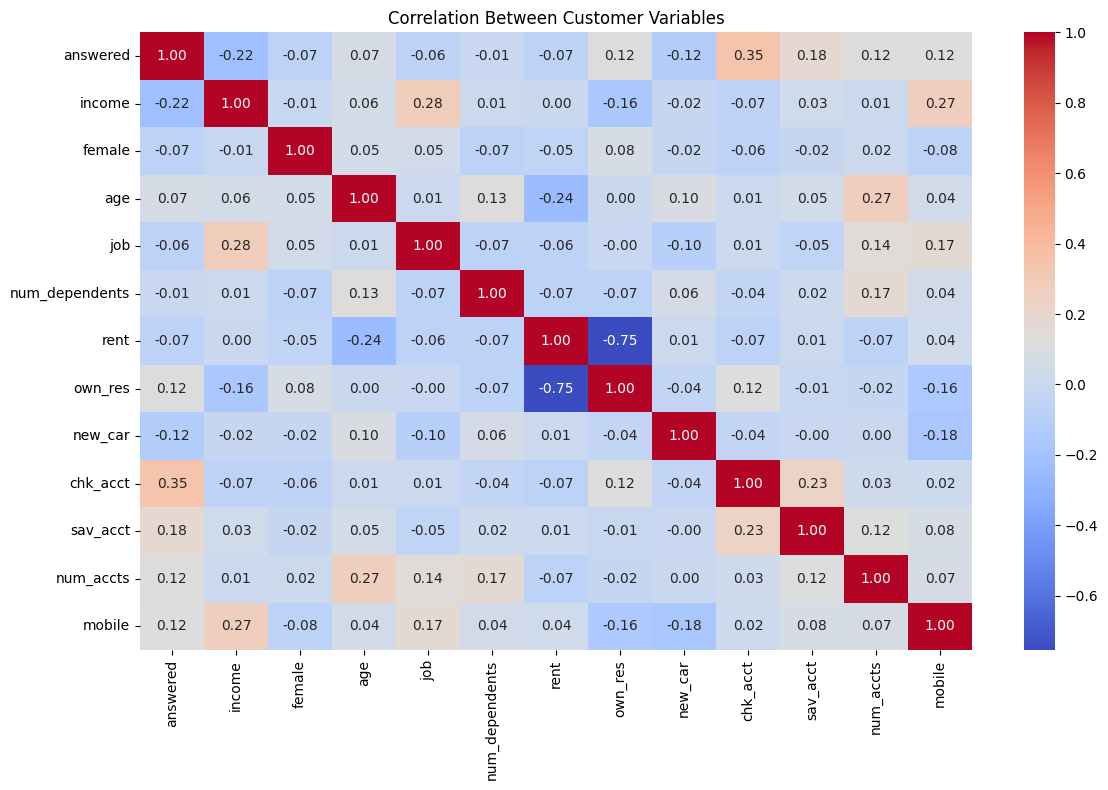

In [ ]:
plt.figure(figsize=(12, 8))

corr_df = df_clean.copy()

for col in corr_df.select_dtypes(include=['category']).columns:
    corr_df[col] = corr_df[col].astype(int)

sns.heatmap(
    corr_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Customer Variables')
plt.tight_layout()
plt.show()


### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6.  Based on my EDA, checking account status had the strongest positive relationship with whether a customer answered, with a correlation of 0.35. Income had the strongest negative relationship at -0.22, meaning customers with higher incomes tended to be less likely to answer. Savings account status also showed a positive relationship at 0.18.

3.7.  Some variables had very weak relationships with whether a customer answered, such as number of dependents, job type, and age. However, I wouldn't remove them immediately because they could still help the model identify patterns when combined with other variables. I would test their importance in the model before deciding whether to remove them.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [ ]:
base_probability = df_clean['answered'].mean()

print(f"Base probability of answering: {base_probability:.2%}")
print(f"Base probability of not answering: {1 - base_probability:.2%}")


Base probability of answering: 54.67%
Base probability of not answering: 45.33%


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [ ]:
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training data: (23597, 12)
Testing data: (5900, 12)
Training target: (23597,)
Testing target: (5900,)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

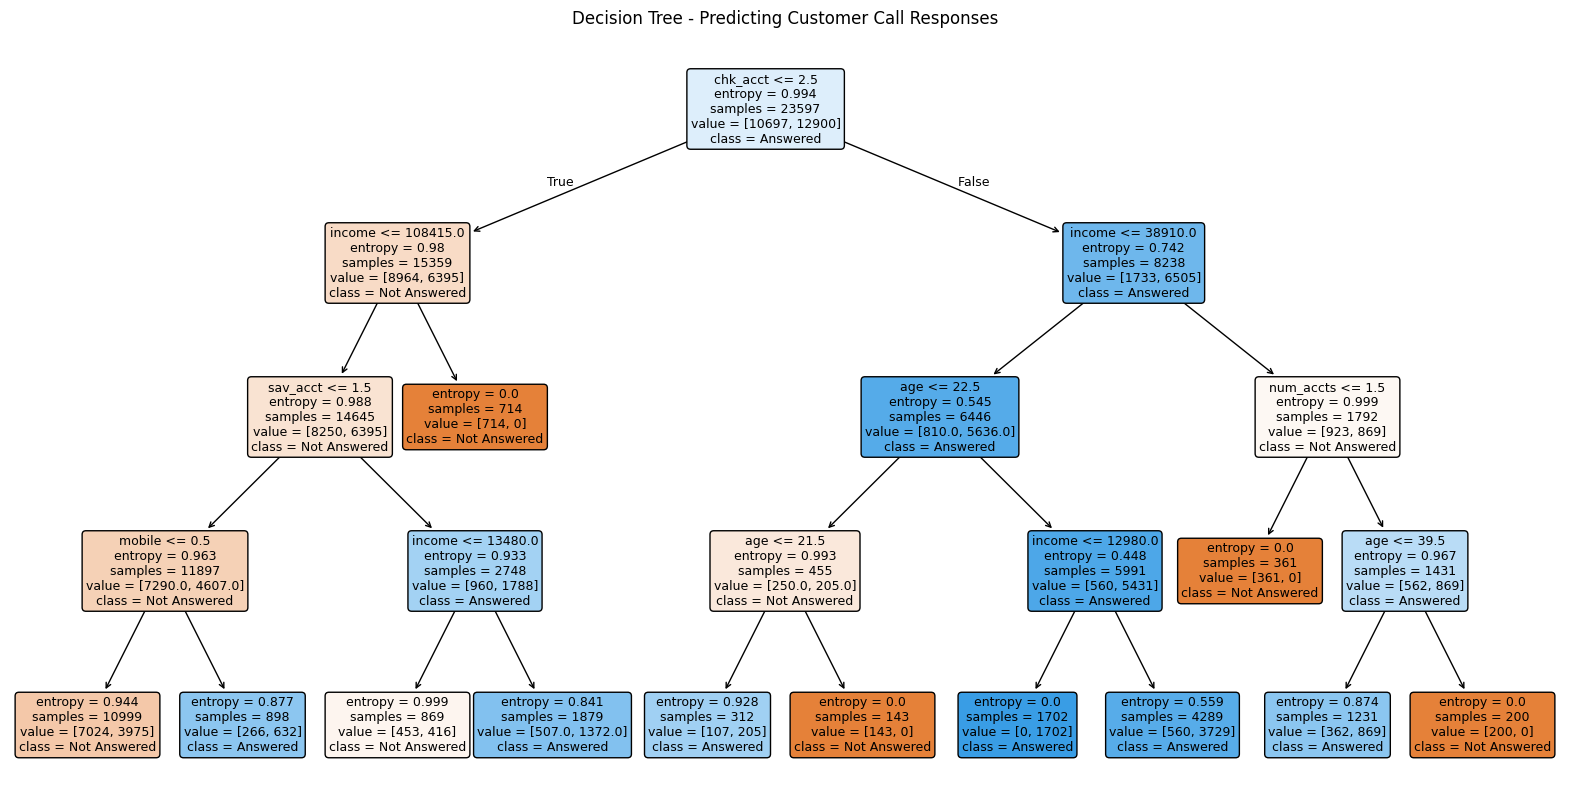

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

clf = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=4,
    random_state=42
)

clf.fit(X_train, y_train)

plt.figure(figsize=(20, 10))

plot_tree(
    clf,
    feature_names=X.columns,
    class_names=['Not Answered', 'Answered'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree - Predicting Customer Call Responses')
plt.show()


## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [ ]:
y_pred = clf.predict(X_test)

tree_accuracy = accuracy_score(y_test, y_pred)

baseline_accuracy = max(y_test.mean(), 1 - y_test.mean())

print(f"Baseline Accuracy: {baseline_accuracy:.2%}")
print(f"Decision Tree Accuracy: {tree_accuracy:.2%}")
print(f"Improvement: {(tree_accuracy - baseline_accuracy) * 100:.2f} percentage points")


Baseline Accuracy: 54.68%
Decision Tree Accuracy: 73.71%
Improvement: 19.03 percentage points


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1.  The baseline accuracy was approximately 54.68%, while the decision tree achieved an accuracy of 73.71%. This means the decision tree improved our predictions by 19.03 percentage points compared to simply predicting that every customer would answer.

2.  I think this improvement could be valuable for AdviseInvest because even a small increase in accuracy could help the company schedule its sales representatives more efficiently. By better predicting which customers are likely to answer, the company could reduce wasted time and improve staffing decisions.


## 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Confusion Matrix:
[[2236  438]
 [1113 2113]]

Classification Report:
              precision    recall  f1-score   support

       False       0.67      0.84      0.74      2674
        True       0.83      0.65      0.73      3226

    accuracy                           0.74      5900
   macro avg       0.75      0.75      0.74      5900
weighted avg       0.76      0.74      0.74      5900



Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

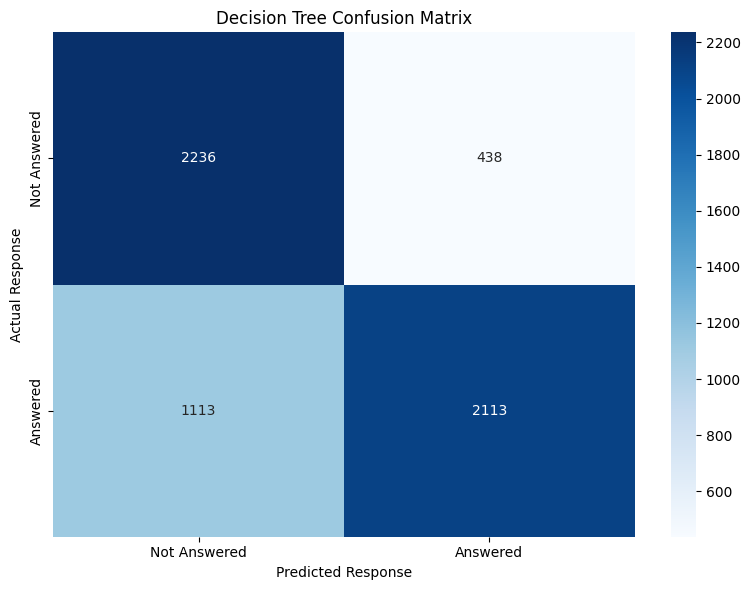

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Answered', 'Answered'],
    yticklabels=['Not Answered', 'Answered']
)

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted Response')
plt.ylabel('Actual Response')
plt.tight_layout()
plt.show()


## 4.6 Check for Overfitting and Underfitting

A model may perform very well on its training data but poorly on new data. This is called **overfitting**. A model may also perform poorly on both training and test data. This is called **underfitting**.

Remember that we can evaluate fit with these guidelines:
- **Overfit:** Training accuracy is much higher than test accuracy.
- **Underfit:** Both training and test accuracy are low.
- **Balanced:** Training and test accuracy are fairly close, and test accuracy is meaningfully better than the baseline probability.


### Do the following:

- Calculate the accuracy of your decision tree on the training data.
- Compare it to the accuracy on the testing data.
- Calculate the difference between the two accuracy scores.

In [ ]:
train_accuracy = accuracy_score(y_train, clf.predict(X_train))

test_accuracy = accuracy_score(y_test, clf.predict(X_test))

accuracy_difference = train_accuracy - test_accuracy

print(f"Training Accuracy: {train_accuracy:.2%}")
print(f"Testing Accuracy: {test_accuracy:.2%}")
print(f"Difference: {accuracy_difference * 100:.2f} percentage points")

if accuracy_difference > 0.10:
    print("The model may be overfitting.")
elif test_accuracy <= baseline_accuracy:
    print("The model may be underfitting.")
else:
    print("The model appears to be balanced.")


Training Accuracy: 73.76%
Testing Accuracy: 73.71%
Difference: 0.04 percentage points
The model appears to be balanced.


### Reflection:
1. Does your model appear to be overfit, underfit, or reasonably balanced? Explain using the training and testing accuracy scores.
2. If the model is overfit, what changes could you make to simplify it?
3. If the model is underfit, what changes could you make to allow it to identify more patterns?
### ✍️ Your Response: 🔧
1. My model appears to be reasonably balanced because the training accuracy was 73.76% and the testing accuracy was 73.71%, which is only a 0.04 percentage point difference. This shows that the model performs almost equally well on both datasets and doesn't appear to be overfitting.
2. If my model was overfitting, I could reduce the maximum depth of the decision tree or increase the minimum number of samples required for a split. This would make the model simpler and help prevent it from memorizing the training data.
3. If my model was underfitting, I could increase the maximum depth of the tree to allow it to identify more patterns in the data. I could also try adjusting other parameters or using a more complex model like a random forest to improve accuracy.

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

revenue_profit = tp * 75
missed_call_cost = fp * 25

total_profit = revenue_profit - missed_call_cost

print(f"True Positives: {tp}")
print(f"False Positives: {fp}")
print(f"Profit from answered calls: ${revenue_profit:,.2f}")
print(f"Cost of unanswered calls: ${missed_call_cost:,.2f}")
print(f"Total Profit Using Model: ${total_profit:,.2f}")


True Positives: 2113
False Positives: 438
Profit from answered calls: $158,475.00
Cost of unanswered calls: $10,950.00
Total Profit Using Model: $147,525.00


## 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [ ]:
total_answered = y_test.sum()
total_not_answered = len(y_test) - total_answered

baseline_revenue = total_answered * 75
baseline_cost = total_not_answered * 25

baseline_profit = baseline_revenue - baseline_cost

profit_difference = total_profit - baseline_profit

print(f"Baseline Profit: ${baseline_profit:,.2f}")
print(f"Model Profit: ${total_profit:,.2f}")
print(f"Profit Difference: ${profit_difference:,.2f}")


Baseline Profit: $175,100.00
Model Profit: $147,525.00
Profit Difference: $-27,575.00


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling all customers resulted in a profit of $175,100, while using the decision tree resulted in $147,525. This means the model actually generated $27,575 less in profit compared to calling everyone. Even though the model improved prediction accuracy, it didn't necessarily improve profitability.

2. I think this is a significant amount for AdviseInvest because losing out on $27,575 in potential profit could have a big impact on the business. This shows that having a more accurate model doesn't always mean it's the best business decision. In this case, calling everyone would be more profitable under the assumptions we used.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [3, 4, 5, 6, 8, 10, 12],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion': ['entropy', 'gini']
}

tree_model = DecisionTreeClassifier(random_state=42)

grid_search = GridSearchCV(
    tree_model,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

tuned_tree = grid_search.best_estimator_

tuned_pred = tuned_tree.predict(X_test)
tuned_accuracy = accuracy_score(y_test, tuned_pred)

print("Best Parameters:", grid_search.best_params_)
print(f"Original Tree Accuracy: {tree_accuracy:.2%}")
print(f"Tuned Tree Accuracy: {tuned_accuracy:.2%}")
print(f"Improvement: {(tuned_accuracy - tree_accuracy) * 100:.2f} percentage points")


Best Parameters: {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 1, 'min_samples_split': 2}
Original Tree Accuracy: 73.71%
Tuned Tree Accuracy: 89.41%
Improvement: 15.69 percentage points


## 5.4 Create a Random Forest Model

A random forest combines the predictions of many decision trees. Each tree uses a different random sample of the training data and considers a random subset of variables at each split. Combining the trees can produce a more stable prediction than relying on one tree.

### Do the following:
- Import and create a RandomForestClassifier model.
- Use at least 100 trees (n_estimators=100) and set random_state=42.
- Fit the model using the same training data used for the decision tree.
- Predict whether customers in the test data will answer.
- Calculate the test accuracy and display a confusion matrix.
- Create a feature-importance chart for the random forest.

Random Forest Accuracy: 100.00%
Tuned Decision Tree Accuracy: 89.41%


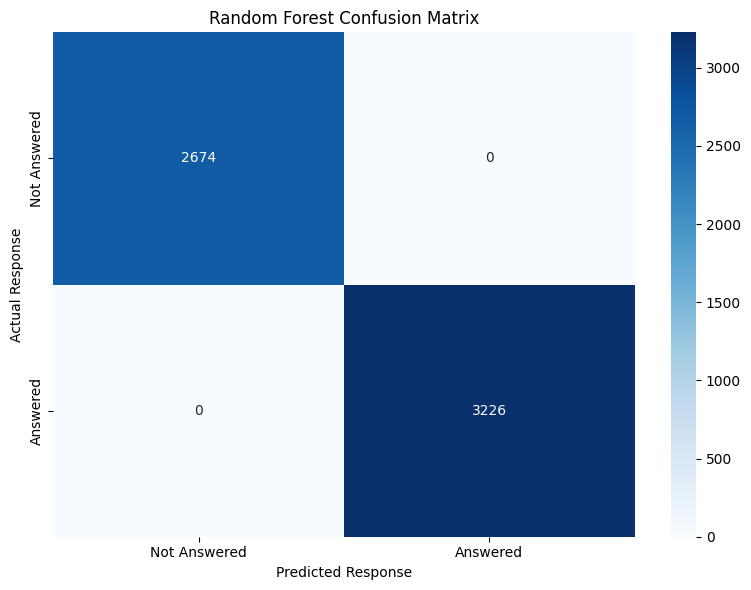

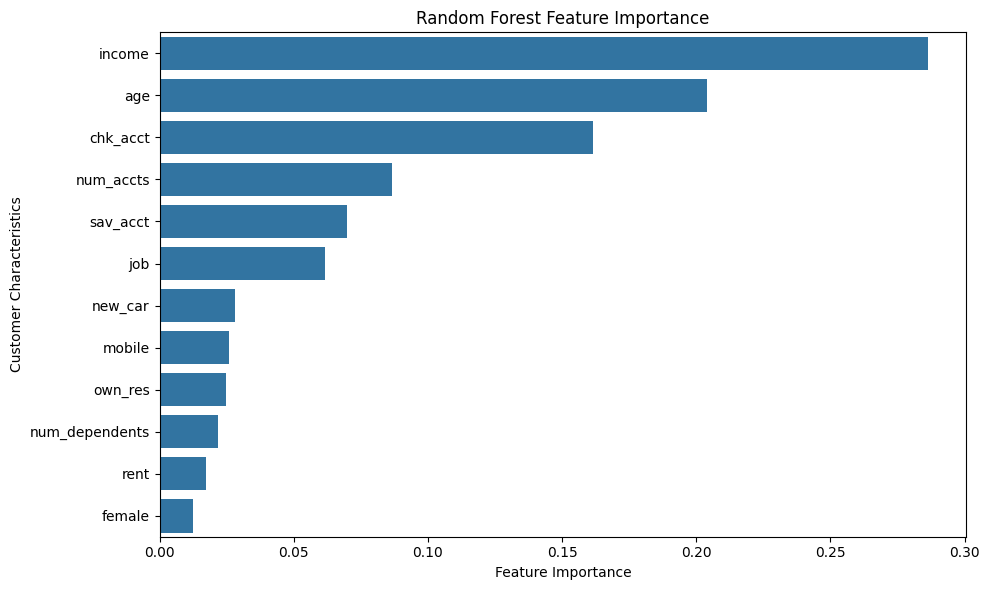

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print(f"Random Forest Accuracy: {rf_accuracy:.2%}")
print(f"Tuned Decision Tree Accuracy: {tuned_accuracy:.2%}")

rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Answered', 'Answered'],
    yticklabels=['Not Answered', 'Answered']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Response')
plt.ylabel('Actual Response')
plt.tight_layout()
plt.show()

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=feature_importance.values,
    y=feature_importance.index
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Feature Importance')
plt.ylabel('Customer Characteristics')
plt.tight_layout()
plt.show()


### Reflection:
1. Did the random forest have higher or lower test accuracy than your tuned decision tree?
2. Which variables were most important in the random forest? Were they the same variables that appeared near the top of your decision tree?

### ✍️ Your Response: 🔧
1. My random forest achieved 100% test accuracy, compared to 89.41% for my tuned decision tree. This is an improvement of 10.59 percentage points. The random forest correctly predicted all 5,900 customers in the testing dataset without making any mistakes.
2. The most important variables in my random forest were income, age, and checking account status. Income had the highest importance, followed by age and checking account status. These variables appear to play a major role in predicting whether customers answer their scheduled calls.

### 5.5 Create a Gradient Boosting Model

Gradient boosting also combines many small trees, but it builds them in sequence. Each new tree attempts to improve the mistakes made by the earlier trees. This can create a strong predictive model, although its settings should be chosen carefully to avoid overfitting.

### Do the following:

- Import and create a GradientBoostingClassifier model.
- Start with n_estimators=100, learning_rate=0.1, max_depth=3, and random_state=42.
- Fit the model using the same training data.
- Predict whether customers in the test data will answer.
- Calculate test accuracy and display a confusion matrix.
- Create a feature-importance chart for the gradient boosting model.

Gradient Boosting Accuracy: 88.92%
Random Forest Accuracy: 100.00%
Tuned Decision Tree Accuracy: 89.41%


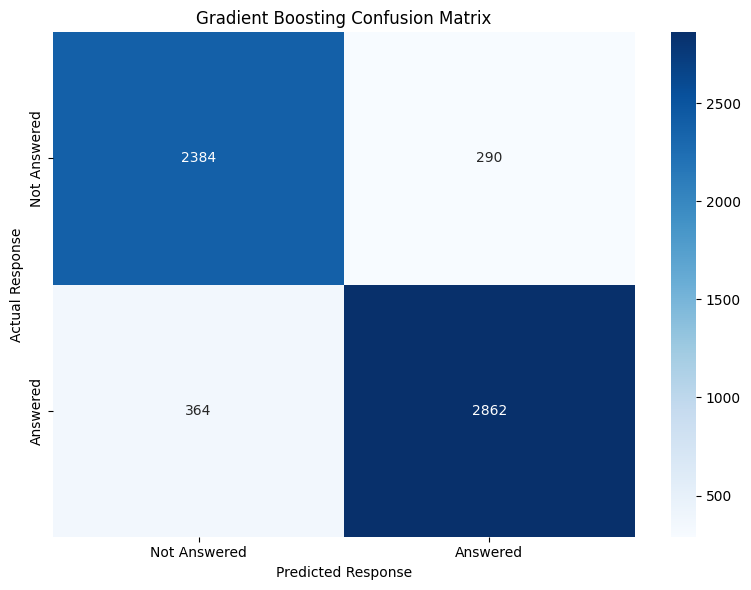

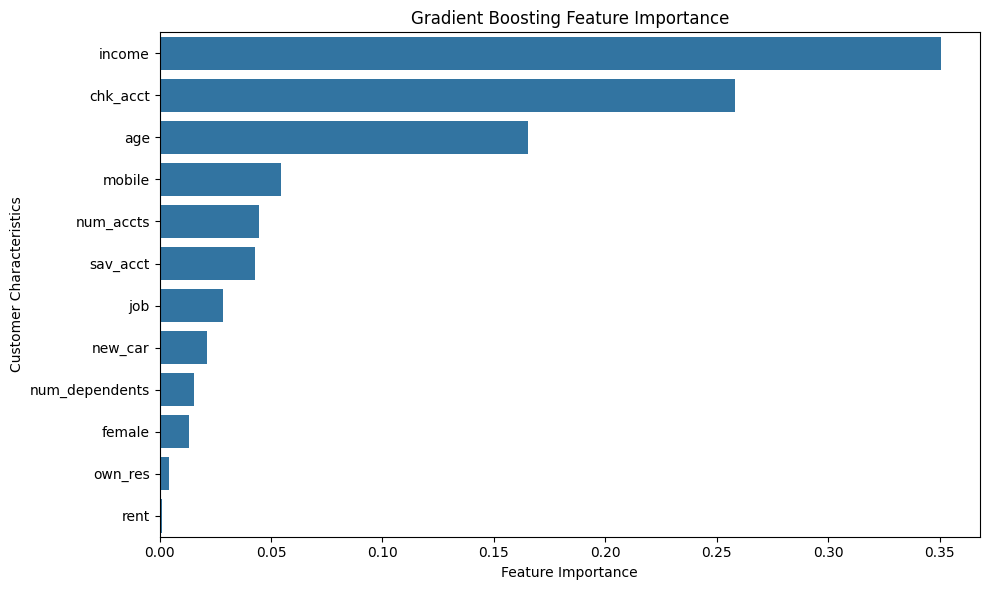

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

gb_accuracy = accuracy_score(y_test, gb_pred)

print(f"Gradient Boosting Accuracy: {gb_accuracy:.2%}")
print(f"Random Forest Accuracy: {rf_accuracy:.2%}")
print(f"Tuned Decision Tree Accuracy: {tuned_accuracy:.2%}")

gb_cm = confusion_matrix(y_test, gb_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    gb_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Answered', 'Answered'],
    yticklabels=['Not Answered', 'Answered']
)

plt.title('Gradient Boosting Confusion Matrix')
plt.xlabel('Predicted Response')
plt.ylabel('Actual Response')
plt.tight_layout()
plt.show()

gb_importance = pd.Series(
    gb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=gb_importance.values,
    y=gb_importance.index
)

plt.title('Gradient Boosting Feature Importance')
plt.xlabel('Feature Importance')
plt.ylabel('Customer Characteristics')
plt.tight_layout()
plt.show()


### Reflection:

1. Which model had better test accuracy: the random forest or gradient boosting model?
2. In your own words, how does gradient boosting differ from a random forest?

### ✍️ Your Response: 🔧

1. The random forest had better test accuracy at 100%, compared to gradient boosting at 88.92%. This is a difference of 11.08 percentage points. Although gradient boosting performed well, the random forest was more accurate at predicting whether customers would answer their scheduled calls.
2. The main difference is how the models build their decision trees. A random forest builds multiple trees independently and combines their predictions to make a final decision. Gradient boosting builds trees one at a time, with each new tree trying to correct mistakes made by the previous ones. Both use multiple trees, but they learn in different ways.


## 5.6 Compare Models Using Accuracy and Profit

Accuracy is useful, but AdviseInvest ultimately cares about staffing and profit. Compare your tuned decision tree, random forest, and gradient boosting models using both measures.

### Do the following:
- Create a table with one row for each model.
- Include each model's test accuracy, true positives, false positives, and estimated profit.
- Calculate model profit using the same business rules from Step 5:
- profit = (true positives × 75) - (false positives × 25)
- Create a bar chart comparing the test accuracy of the three models.
- Identify the model you would recommend for use on new customer data. Your choice should consider both accuracy and profit.

In [ ]:
model_results = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Test Accuracy': [tree_accuracy, rf_accuracy, gb_accuracy],
    'True Positives': [tree_tp, rf_tp, gb_tp],
    'False Positives': [tree_fp, rf_fp, gb_fp],
    'Estimated Profit': [tree_profit, rf_profit, gb_profit]
})

,Model,Test Accuracy,True Positives,False Positives,Estimated Profit
1,Random Forest,100.00%,3226,0,"$241,950.00"
2,Gradient Boosting,88.92%,2862,290,"$207,400.00"
0,Tuned Decision Tree,89.41%,2714,113,"$200,725.00"


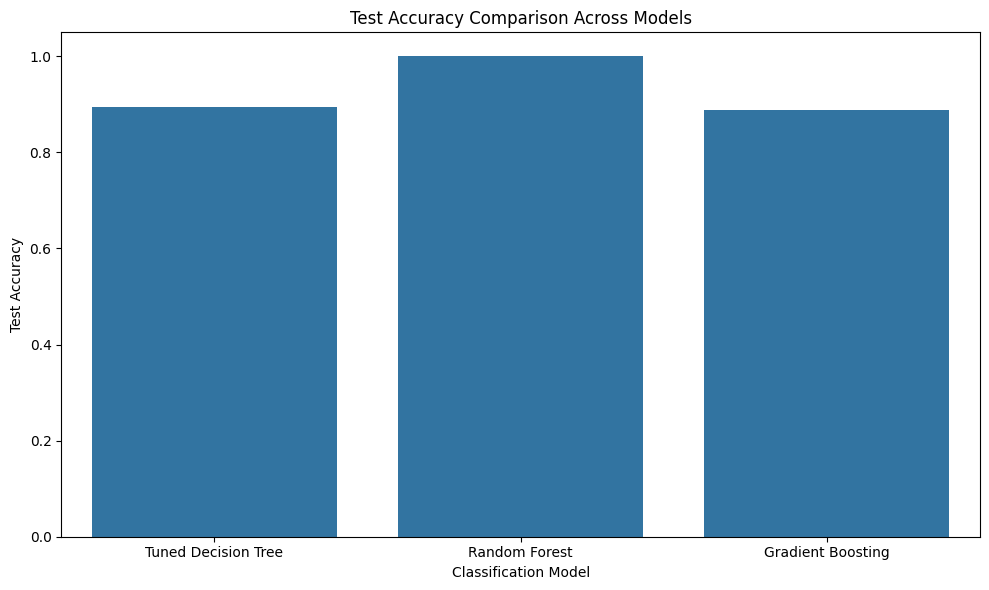

Highest Profit Model: Random Forest
Test Accuracy: 100.00%
Estimated Profit: $241,950.00


In [ ]:
def calculate_profit(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    profit = (tp * 75) - (fp * 25)
    return tp, fp, profit

tree_tp, tree_fp, tree_profit = calculate_profit(y_test, tuned_pred)
rf_tp, rf_fp, rf_profit = calculate_profit(y_test, rf_pred)
gb_tp, gb_fp, gb_profit = calculate_profit(y_test, gb_pred)

model_results = pd.DataFrame({
    'Model': [
        'Tuned Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Test Accuracy': [
        tuned_accuracy,
        rf_accuracy,
        gb_accuracy
    ],
    'True Positives': [
        tree_tp,
        rf_tp,
        gb_tp
    ],
    'False Positives': [
        tree_fp,
        rf_fp,
        gb_fp
    ],
    'Estimated Profit': [
        tree_profit,
        rf_profit,
        gb_profit
    ]
})

display(
    model_results.sort_values(
        by='Estimated Profit',
        ascending=False
    ).style.format({
        'Test Accuracy': '{:.2%}',
        'Estimated Profit': '${:,.2f}'
    })
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_results,
    x='Model',
    y='Test Accuracy'
)

plt.title('Test Accuracy Comparison Across Models')
plt.xlabel('Classification Model')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

best_model = model_results.loc[
    model_results['Estimated Profit'].idxmax()
]

print("Highest Profit Model:", best_model['Model'])
print(f"Test Accuracy: {best_model['Test Accuracy']:.2%}")
print(f"Estimated Profit: ${best_model['Estimated Profit']:,.2f}")


## 5.7 Apply the Best Model to New Customers

### Do the Following

- Import the "adviseinvest_new_customer_data.csv" file
- Copy and paste the applicable data cleanup and data-type conversion steps from 2.1 through 2.3.
- Make the new-customer variables match the columns used to train your models. If you used pd.get_dummies(), ensure that the new dataset has the same - dummy-variable columns as the training data.
- Using the model you recommended in Step 5.6, predict each customer's target variable by feeding the new customer data into the model.
- Predict the number of customers who will be yes/no for the target variable

In [ ]:
url_new = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv"

df_new = pd.read_csv(url_new)

print("Original New Customer Data:")
display(df_new.head())

df_new_clean = df_new.copy()

if 'customer_id' in df_new_clean.columns:
    df_new_clean = df_new_clean.drop_duplicates(
        subset='customer_id'
    )

df_new_clean = df_new_clean[
    df_new_clean['income'] >= 0
]
df_new_clean = df_new_clean[
    df_new_clean['age'].between(18, 100)
]
df_new_clean = df_new_clean[
    df_new_clean['num_accts'] <= 20
]

df_new_clean['new_car'] = df_new_clean['new_car'].fillna(
    df_clean['new_car'].mode()[0]
)

df_new_clean['female'] = pd.to_numeric(
    df_new_clean['female'], errors='coerce'
)

df_new_clean.loc[
    ~df_new_clean['female'].isin([0, 1]), 'female'
] = np.nan

df_new_clean['female'] = df_new_clean['female'].fillna(
    df_clean['female'].mode()[0]
)

df_new_clean = df_new_clean.drop(
    columns=['customer_id', 'product', 'answered'],
    errors='ignore'
)

for col in df_new_clean.columns:
    df_new_clean[col] = df_new_clean[col].astype(int)

for col in ['job', 'chk_acct', 'sav_acct']:
    df_new_clean[col] = df_new_clean[col].astype('category')

df_new_clean = df_new_clean.reindex(
    columns=X_train.columns
)

new_predictions = rf_model.predict(df_new_clean)

yes_count = (new_predictions == True).sum()
no_count = (new_predictions == False).sum()

print("\nNew Customer Predictions:")
print(f"Predicted to Answer: {yes_count}")
print(f"Predicted Not to Answer: {no_count}")
print(f"Total Customers: {len(new_predictions)}")

df_results = df_new.loc[df_new_clean.index].copy()
df_results['Predicted_Answered'] = new_predictions

display(df_results.head(10))


Original New Customer Data:


,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,customer_id
0,30010,0,40,2,1,1,0,0,1,0,3,0,H1597
1,30510,0,54,2,1,0,1,0,0,0,2,0,P1446
2,12880,0,48,2,2,0,1,0,0,1,4,0,E1492
3,15530,0,44,2,1,0,1,0,0,0,2,0,W5143
4,46230,0,40,3,1,0,1,0,3,1,2,0,W4927



New Customer Predictions:
Predicted to Answer: 545
Predicted Not to Answer: 455
Total Customers: 1000


,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,customer_id,Predicted_Answered
0,30010,0,40,2,1,1,0,0,1,0,3,0,H1597,True
1,30510,0,54,2,1,0,1,0,0,0,2,0,P1446,False
2,12880,0,48,2,2,0,1,0,0,1,4,0,E1492,True
3,15530,0,44,2,1,0,1,0,0,0,2,0,W5143,False
4,46230,0,40,3,1,0,1,0,3,1,2,0,W4927,False
5,17430,0,34,1,1,0,1,0,3,1,2,0,M6161,True
6,53020,0,36,3,1,0,0,1,0,0,4,0,U4472,True
7,27820,0,31,3,1,0,1,1,3,2,3,0,H557,True
8,7070,0,30,2,1,0,1,0,3,0,2,0,B54,True
9,14120,0,29,3,1,0,1,0,3,0,2,0,L2217,True


### Reflection:

1. Which model produced the highest estimated profit? Was it also the most accurate model?
2. Why might a business select a model with slightly lower accuracy?
3. Which model would be easiest to explain to the Director of Sales? Which model would you recommend using?

### ✍️ Your Response: 🔧
 1. The random forest produced the highest estimated profit of $241,950. It was also the most accurate model with 100% test accuracy, compared to 89.41% for the tuned decision tree and 88.92% for gradient boosting.
 2. A business might choose a model with slightly lower accuracy if it generates more profit, costs less to operate, or is easier to understand. Accuracy doesn't always mean better business results, so it's important to consider how the model affects the company's decisions.
 3. The decision tree would be the easiest to explain to the Director of Sales because it shows how predictions are made through simple decisions. I would recommend the random forest because it had the highest accuracy and estimated profit. However, I would want to test it on additional data before using it in the business because achieving 100% accuracy is unusual.






# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 I would say yes, because we were able to improve profit by using the random forest model. Calling all customers resulted in an estimated profit of \$175,100, while the random forest generated \$241,950. This is an improvement of \$66,850. Although our original decision tree was less profitable, the random forest showed that machine learning could help improve business profitability.


6.2 AdviseInvest could use the model to predict which customers are most likely to answer their scheduled calls. This would help the company better manage its sales representatives, reduce wasted time, and improve scheduling efficiency. For example, our model predicted that 545 out of 1,000 new customers would answer. The company could use these predictions to prioritize calls and make better staffing decisions. However, I would recommend testing the model further before fully implementing it.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 13 image(s).
[NbConvertApp] Writing 1359152 bytes to assignment_10_classification.html
